# ESS LLRF anomaly detection on a feature store

Three programs that share only the feature store and the model registry, on the full challenge data:

| Step | Program | Reads | Writes |
|---|---|---|---|
| Feature | `feature_pipeline.py` | `ess_llrf_waveforms` (project `m4cast_ess`, read-only) | `ess_waveform_features` (your project) |
| Training | `training_pipeline.py` | both groups, through two feature views | models `ess_llrf_anomaly`, `ess_llrf_autoencoder` |
| Inference | `inference_pipeline.py` | the model, the online store | deployment `essanomaly` |

This notebook walks the same steps and only reads, so it runs from a laptop. Before starting it: `hops project use <your project>`, a project with the real stores shared into it (track 03). The writes are shown as commands for the terminal of your project. `README.md` has the numbers of a full run.

In [1]:
import hopsworks
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from feature_pipeline import EVENT_TIME, KEYS, RF_ON, SOURCE_FG, STORE, build

## 1. Read the real group

One row is one acquisition cycle of one RF chain: `i` and `q` at 256 points. The key is `event_id`, `cycle_id`, `pv_base`. The pipeline drops repeated keys as a guard; the group holds none.

In [2]:
project = hopsworks.login()
real = project.get_feature_store(name=STORE)
source = real.get_feature_group(SOURCE_FG, version=1)
waves = source.select([*KEYS, EVENT_TIME, "i", "q", "in_sample_holdout"]).read()
print(len(waves), "rows read")
waves = waves.drop_duplicates(KEYS).reset_index(drop=True)
print(len(waves), "keys,", waves.event_id.nunique(), "captures,", waves.pv_base.nunique(), "chains,", int(waves.in_sample_holdout.sum()), "holdout rows")

2026-10-12 14:02:02,742 INFO: Initializing external client


2026-10-12 14:02:02,742 INFO: Base URL: https://aissai26.hops.live:443


Using the API key cached by `hops setup` for aissai26.hops.live


2026-10-12 14:02:03,974 INFO: Python Engine initialized.



Logged in to project, explore it here https://aissai26.hops.live:443/p/1145


Finished: Reading data from Hopsworks, using Hopsworks Feature Query Service (4.02s) 
52842 rows read
52842 keys, 108 captures, 28 chains, 42 holdout rows


`i` is an amplitude envelope. `q` stays within ±180 and wraps, as a phase in degrees does. One capture on one chain, cycle after cycle: eleven cycles overlap, and the last one stops early.

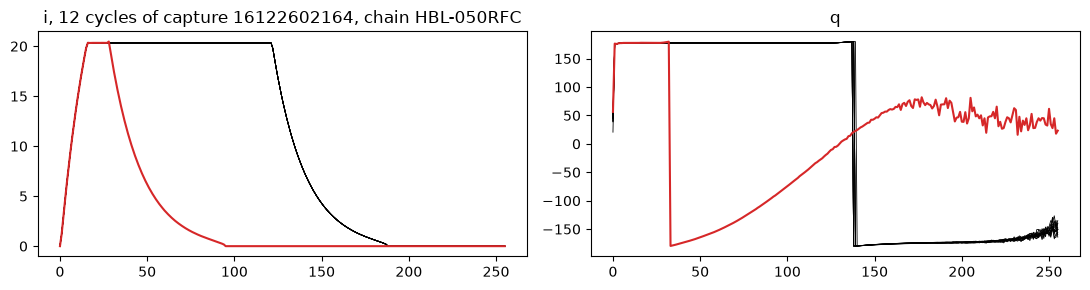

In [3]:
capture = waves[(waves.event_id == 16122602164) & waves.pv_base.str.startswith("HBL-050RFC")].sort_values("cycle_id")
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
for k, row in enumerate(capture.itertuples()):
    last = k == len(capture) - 1
    ax[0].plot(row.i, color="tab:red" if last else "black", lw=1.5 if last else 0.6)
    ax[1].plot(row.q, color="tab:red" if last else "black", lw=1.5 if last else 0.6)
ax[0].set_title(f"i, {len(capture)} cycles of capture 16122602164, chain HBL-050RFC")
ax[1].set_title("q")
plt.tight_layout()

## 2. Feature pipeline

`build` turns each row into 14 features: flat-top level, length, ripple and droop, rise and fall, phase level and drift while the RF is on, noise, and the distance of the cycle from the other cycles of the same capture on the same chain.

In [4]:
features = build(waves)
print(features.shape)
features.drop(columns=[*KEYS, EVENT_TIME]).describe().T[["mean", "std", "min", "max"]]

(52842, 18)


,mean,std,min,max
i_max,12.614972,4.493019,0.000000,20.463232
i_flat_level,12.592328,4.485220,0.000000,20.331247
i_flat_len,70.591102,33.106770,1.000000,256.000000
i_flat_ripple,0.003024,0.001230,0.000000,0.022346
i_droop,-0.000849,0.002855,-0.015378,0.009118
i_rise,15.094073,2.648291,0.000000,214.000000
i_fall,37.480205,10.903516,1.000000,114.000000
i_tail_noise,0.000198,0.000483,0.000000,0.003993
q_flat_mean,50.827560,98.289771,-173.911833,178.250245
q_flat_std,0.294891,1.406078,0.000000,115.252626


In [5]:
features[(features.event_id == 16122602164) & features.pv_base.str.startswith("HBL-050RFC")].sort_values("cycle_id").tail(4)[["cycle_id", "i_flat_level", "i_flat_len", "i_cycle_dev", "q_cycle_dev"]]

,cycle_id,i_flat_level,i_flat_len,i_cycle_dev,q_cycle_dev
52389,16122596484,20.329910,108,0.001277,0.107694
52384,16122596498,20.330507,108,0.001065,0.071471
52379,16122596512,20.330621,108,0.001324,0.013337
52374,16122596526,20.330223,13,11.104937,98.125244


In the terminal of your project, the same frame becomes an online feature group on the key and event time of the real group:

```bash
python feature_pipeline.py --insert
```

## 3. Training pipeline

No confirmed fault labels exist, so the model learns the envelope of the cycles: a scaler and an IsolationForest on the 14 features. The 42 rows the organisers score on are left out of training. On the cluster the frame comes from a feature view, and the model is registered with it:

```python
fv = fs.get_or_create_feature_view(name="ess_llrf_anomaly", version=1,
    query=features_fg.select_except([*KEYS, EVENT_TIME]))
X, _ = fv.training_data(primary_key=True)
```

The same model, fitted here on the frame of step 2:

In [6]:
names = [c for c in features.columns if c not in (*KEYS, EVENT_TIME)]
holdout = waves.in_sample_holdout.to_numpy()
model = make_pipeline(StandardScaler(), IsolationForest(n_estimators=300, contamination=0.01, random_state=42, n_jobs=-1))
model.fit(features.loc[~holdout, names])
features["score"] = -model.score_samples(features[names])
features["flagged"] = model.predict(features[names]) == -1

rf_off = features.i_max < RF_ON * features.groupby("pv_base").i_max.transform("median")
cut = ~rf_off & (features.i_flat_len < 0.5 * features.groupby(["event_id", "pv_base"]).i_flat_len.transform("median"))
groups = {"all rows": np.ones(len(features), dtype=bool), "holdout": holdout, "RF off": rf_off.to_numpy(), "pulse cut short": cut.to_numpy()}
pd.DataFrame({"rows": {k: int(m.sum()) for k, m in groups.items()}, "flagged": {k: int(features.flagged[m].sum()) for k, m in groups.items()}})

,rows,flagged
all rows,52842,532
holdout,42,4
RF off,269,269
pulse cut short,14,14


The rows with the RF off score highest, then the cut pulses. Where the cut pulses rank among all rows:

In [7]:
sorted(features.score.rank(ascending=False)[cut].astype(int))

[254, 256, 263, 264, 267, 268, 269, 272, 273, 276, 279, 280, 281, 284]

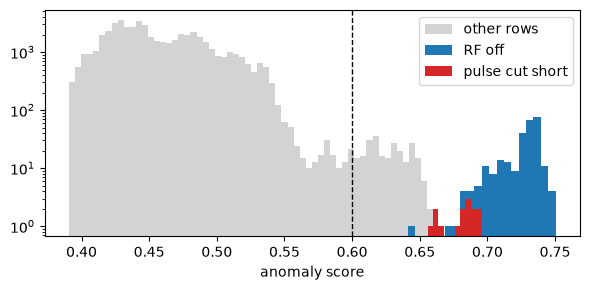

In [8]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(features.score[~rf_off & ~cut], bins=60, color="lightgrey", label="other rows")
ax.hist(features.score[rf_off], bins=20, color="tab:blue", label="RF off")
ax.hist(features.score[cut], bins=10, color="tab:red", label="pulse cut short")
ax.axvline(-model[-1].offset_, color="black", ls="--", lw=1)
ax.set_yscale("log"); ax.set_xlabel("anomaly score"); ax.legend()
plt.tight_layout()

The second model is the challenge's own autoencoder, trained on every row outside the holdout and scored with the organisers' `score.py`. It needs `torch`:

```bash
python training_pipeline.py                       # both models, registered with their feature views
python training_pipeline.py --only ess_llrf_autoencoder --strict
```

## 4. Inference

In the terminal of your project. The deployment receives keys, looks the 14 features up in the online store, and returns `[score, flagged]` per key:

```bash
python inference_pipeline.py --event 16122602164
```

```python
deployment.predict(inputs=[{"event_id": 16122602164, "cycle_id": 16122596526,
                            "pv_base": "HBL-050RFC:RFS-DIG-101:Dwn0-CmpSDS-PMData"}])
# {'predictions': [[0.6469190320102919, True]]}
```

The score of that row from the model fitted in this notebook. A new fit reads the rows in another order, so its score differs from the deployed model's in the second decimal:

In [9]:
features[(features.event_id == 16122602164) & (features.cycle_id == 16122596526) & features.pv_base.str.startswith("HBL-050RFC")][[*KEYS, "score", "flagged"]]

,event_id,cycle_id,pv_base,score,flagged
52374,16122602164,16122596526,HBL-050RFC:RFS-DIG-101:Dwn0-CmpSDS-PMData,0.660881,True
